                               photos  samples  px_per_mm
split camera                                             
test  iPhone 14                    14        3       13.9
      iPhone 16                    21        7       19.5
train Motorola Edge                69       22        4.6
      Motorola Edge 60 Fusion       3        1       12.5
      Samsung A52                  55       22        4.6
train-like target: 4.597 px/mm
162 photos, 22 features in 312 s
representation floor: Weibull 7.65 → +2 residual PCs 4.62
LOSO A1 (Weibull):       48.24
LOSO A2 (Weibull+resid): 47.96
blend mu: {0.0: 48.24, 0.25: 47.9, 0.5: 47.72, 0.75: 47.75, 1.0: 47.96} → mu* = 0.5
lambda: {0.0: 47.72, 0.25: 46.49, 0.5: 45.85, 0.75: 45.56, 1.0: 45.72} → lambda* = 0.75
HONEST LOSO CV (blend + calibration): 45.56
type
fine      46.9
gravel    34.5
sand      51.2
cross-phone CV (weighted): 57.91  (21 samples)
alphas per fold: [8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 1.0, 8.0, 8.0] → final 8.0
  

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

SAM on GPU
measuring 38 photos


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


SAM done in 219 s
                          photos    A63    A20    G63    G20  cover  max_stone_mm
sample_id                                                                        
HPC_Muenster_BS6_9_0-10m       5  0.249  0.712  0.128  0.671  0.820       103.702
HPC_Testfeld Lidl WHV          4  0.000  0.433  0.000  0.345  0.618        46.593
H374                           3  0.015  0.192  0.000  0.142  0.316        64.813
HPC_Audorfring                 5  0.000  0.064  0.000  0.041  0.160        42.208
HPC_Airbus BS10-4bis7          3  0.000  0.004  0.000  0.004  0.022        28.983
HPC_Kleinkummerfeld 2-3        3  0.000  0.002  0.000  0.000  0.005        22.022
HPC_Airbus BS6-3               3  0.000  0.002  0.000  0.000  0.013        21.813
HPC_Airbus BS12-5bis8          3  0.000  0.000  0.000  0.000  0.010        17.747
HPC_Kleinkummerfeld 18-3       3  0.000  0.000  0.000  0.000  0.001        10.166
HPC_Kleinkummerfeld 2-2        3  0.000  0.000  0.000  0.000  0.006        18.06

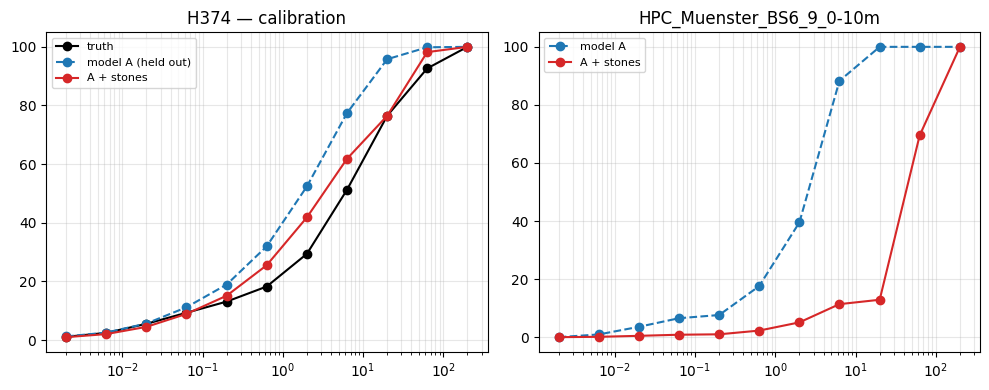

In [1]:
# %% [0] ── SOIL GRAIN SIZE — enhanced texture model (v2) ────────────────────
# Changes vs v1 (LB 36.19 / user-best 34.3):
#   * 22 physically-scaled features: DoG bands + granulometry (open/close) + FFT + tiles
#   * Weibull + 2 residual-PCA dims (representation floor printed)
#   * L1-consistent everywhere: median aggregation, L1-PAVA monotone projection,
#     L1 isotonic recalibration with nested-LOO strength selection
#   * inner-CV alpha selection; blend weight mu selected on OOF; SAM brightness normalization
import io, re, time, unicodedata
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

IS_KAGGLE = Path("/kaggle/input").exists()
INPUT_DIR = sorted(Path("/kaggle/input").glob("**/Training_labels_updated.csv"))[0].parent if IS_KAGGLE else Path("input")
OUTPUT_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SIZES = [0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2, 6.3, 20, 63, 200]
SIZE_COLS = ["0.002", "0.0063", "0.02", "0.063", "0.2", "0.63", "2", "6.3", "20", "63", "200"]
W_EMD = np.diff(np.log10(SIZES))          # all ≈ 0.5 → EMD ≈ 0.5 * sum |ΔF| (L1!)
CAM_EDGE, CAM_A52 = "Motorola Edge", "Samsung A52"

CFG = {
    "target_ppm": 4.5, "crop_frac": 0.5, "n_tiles": 5,          # n_tiles=1 → fast run
    "dog_sigmas_mm": [0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0],
    "gran_scales_mm": [0.5, 1.0, 2.0, 4.0, 8.0, 16.0],
    "fft_bands_mm": [(0.5, 0.7), (0.7, 1.4), (1.4, 2.8)],
    "train_like_above_ppm": 6.0,
    "alpha_grid": [0.5, 1.0, 2.0, 4.0, 8.0],
    "n_resid_pcs": 2, "resid_clip": 15.0,
    "blend_grid": [0.0, 0.25, 0.5, 0.75, 1.0],
    "lam_grid": [0.0, 0.25, 0.5, 0.75, 1.0],
    "weights_group": {"gravel": 0.2, "non_gravel": 0.8},
    "grid_lnb": [-6.0, 4.0, 41], "grid_c": [0.1, 2.0, 39], "c_floor": 0.02,
    "sam_model": "facebook/sam-vit-base", "sam_min_ppm": 12.0, "work_ppm": 2.0, "work_crop": 0.12,
    "sam_normalize": True, "k_override": None,                   # set float to force k (e.g. your 34.3 tuning)
    "pred_iou_thresh": 0.86, "stability_score_thresh": 0.9, "points_per_batch": 64,
    "overlap_drop": 0.5, "min_fill": 0.35, "min_side_mm": 8.0, "max_area_frac": 0.5,
    "apply_if_A63_ge": 0.02,
}

# %% [1] ── index the photos (unchanged from v1) ─────────────────────────────
CAMERA_RE = re.compile(r"^(Motorola_Edge_60_fusion|Motorola_Edge|Samsung_A52|iPhone_?14|iPhone_?16)_(.+?)(?:_\d+| \(\d+\))?$")
CAMERA_KEY = {"Motorola_Edge_60_fusion": "Motorola Edge 60 Fusion", "Motorola_Edge": CAM_EDGE, "Samsung_A52": CAM_A52,
              "iPhone14": "iPhone 14", "iPhone_14": "iPhone 14", "iPhone16": "iPhone 16", "iPhone_16": "iPhone 16"}

def normalize_id(raw: str) -> str:
    s = unicodedata.normalize("NFC", raw).replace("ü", "ue").replace("ö", "oe").replace("ä", "ae")
    return s.replace(",", "_")

labels = pd.read_csv(INPUT_DIR / "Training_labels_updated.csv", dtype={"sample_id": str}).set_index("sample_id")
sample_sub = pd.read_csv(INPUT_DIR / "sample_submission.csv", dtype={"sample_id": str})
ppm_tab = pd.read_csv(INPUT_DIR / "ppm_updated.csv").set_index("phone")

rows = []
for split, pattern in [("train", "Training-All_Photos*"), ("test", "Test_All_Photos*")]:
    for p in sorted(INPUT_DIR.glob(f"{pattern}/**/*")):
        if p.suffix.lower() not in {".jpg", ".jpeg"}:
            continue
        m = CAMERA_RE.match(unicodedata.normalize("NFC", p.stem))
        if m is None:
            raise ValueError(f"unexpected file name: {p.name}")
        with Image.open(p) as im:
            w, h = im.size
        rows.append({"split": split, "path": p, "camera": CAMERA_KEY[m.group(1)],
                     "sample_id": normalize_id(m.group(2)), "w": w, "h": h})
photos = pd.DataFrame(rows)
photos["ppm_eff"] = [ppm_tab.loc[c, "ppm"] * max(w, h) / ppm_tab.loc[c, "width"]
                     for c, w, h in zip(photos.camera, photos.w, photos.h, strict=True)]
assert sorted(set(photos.query("split == 'train'").sample_id)) == sorted(labels.index)
assert set(photos.query("split == 'test'").sample_id) == set(sample_sub.sample_id)

lab = labels.copy()
lab["type"] = np.select([lab["0.063"] >= 40, (lab["63"] - lab["2"]) >= 40], ["fine", "gravel"], "sand")
lab["group"] = np.where(lab["type"] == "gravel", "gravel", "non_gravel")
print(photos.groupby(["split", "camera"]).agg(photos=("path", "size"), samples=("sample_id", "nunique"),
                                              px_per_mm=("ppm_eff", "median")).round(1))

# %% [2] ── features: train-like path → 4.5 px/mm → 5 tiles → median ─────────
_train_small = photos[(photos.split == "train") & (photos.ppm_eff <= CFG["train_like_above_ppm"])]
TRAIN_LIKE_PPM = float(_train_small.ppm_eff.median())
TRAIN_QTABLES = Image.open(sorted(_train_small[_train_small.camera == CAM_A52].path)[0]).quantization
print(f"train-like target: {TRAIN_LIKE_PPM:.3f} px/mm")

def to_train_like(rgb, ppm_eff):
    f = TRAIN_LIKE_PPM / ppm_eff
    small = cv2.resize(rgb, (round(rgb.shape[1] * f), round(rgb.shape[0] * f)), interpolation=cv2.INTER_AREA)
    buf = io.BytesIO()
    Image.fromarray(small).save(buf, format="JPEG", qtables=TRAIN_QTABLES, subsampling=2)
    return np.asarray(Image.open(io.BytesIO(buf.getvalue())).convert("RGB")), TRAIN_LIKE_PPM

def load_gray_base(path, ppm_eff):
    im = ImageOps.exif_transpose(Image.open(path))
    if ppm_eff > CFG["train_like_above_ppm"]:
        rgb, ppm_eff = to_train_like(np.asarray(im.convert("RGB")), ppm_eff)
        im = Image.fromarray(rgb)
    a = np.asarray(im.convert("L"))
    if a.shape[0] > a.shape[1]:
        a = np.ascontiguousarray(np.rot90(a))
    f = CFG["target_ppm"] / ppm_eff
    a = cv2.resize(a, (round(a.shape[1] * f), round(a.shape[0] * f)), interpolation=cv2.INTER_AREA)
    return a.astype(np.float32)

def tiles(a):
    h, w = a.shape
    ch, cw = int(h * CFG["crop_frac"]), int(w * CFG["crop_frac"])
    pos = [((h - ch) // 2, (w - cw) // 2)]
    if CFG["n_tiles"] >= 5:
        pos += [(int(0.10 * h), int(0.10 * w)), (int(0.10 * h), int(0.90 * w) - cw),
                (int(0.90 * h) - ch, int(0.10 * w)), (int(0.90 * h) - ch, int(0.90 * w) - cw)]
    for y, x in pos:
        yield a[y:y + ch, x:x + cw]

def dog_features(g):
    blurs = [cv2.GaussianBlur(g, (0, 0), s * CFG["target_ppm"]) for s in CFG["dog_sigmas_mm"]]
    sd = float(g.std()) + 1e-6
    return {f"dog_{s}mm": float(np.log(np.std(blurs[k - 1] - blurs[k]) / sd + 1e-6))
            for k, s in enumerate(CFG["dog_sigmas_mm"]) if k > 0}

def _morph_mean(g, s_mm, op):
    """Mean gray after opening/closing at physical scale s_mm (pyramid trick for big SEs)."""
    r = max(s_mm * CFG["target_ppm"], 1.5)
    if r <= 24:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(round(r)) + 1,) * 2)
        return float(cv2.morphologyEx(g, op, k).mean())
    f = r / 24.0
    small = cv2.resize(g, (max(int(round(g.shape[1] / f)), 60), max(int(round(g.shape[0] / f)), 60)),
                       interpolation=cv2.INTER_AREA)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (49, 49))
    return float(cv2.morphologyEx(small, op, k).mean())

def gran_features(g):
    """Matheron granulometry: how much bright (open) / dark (close) texture lives at each size."""
    sd = float(g.std()) + 1e-6
    o = [_morph_mean(g, s, cv2.MORPH_OPEN) for s in CFG["gran_scales_mm"]]
    c = [_morph_mean(g, s, cv2.MORPH_CLOSE) for s in CFG["gran_scales_mm"]]
    out = {}
    for k in range(len(CFG["gran_scales_mm"]) - 1):
        s = CFG["gran_scales_mm"][k + 1]
        out[f"open_{s}mm"] = float(np.log(max(o[k] - o[k + 1], 1e-3) / sd + 1e-9))
        out[f"close_{s}mm"] = float(np.log(max(c[k + 1] - c[k], 1e-3) / sd + 1e-9))
    return out

def fft_features(g):
    a = g - float(g.mean())
    h, w = a.shape
    win = np.hanning(h)[:, None] * np.hanning(w)[None, :]
    F = np.fft.rfft2((a * win).astype(np.float32))
    p = F.real ** 2 + F.imag ** 2
    fy = np.fft.fftfreq(h)[:, None] * CFG["target_ppm"]
    fx = np.fft.rfftfreq(w)[None, :] * CFG["target_ppm"]
    fr = np.sqrt(fy ** 2 + fx ** 2)                     # cycles per mm
    tot = float(p[fr > 0].mean()) + 1e-12
    out = {}
    for lo, hi in CFG["fft_bands_mm"]:
        m = (fr > 1.0 / hi) & (fr <= 1.0 / lo)
        out[f"fft_{lo}-{hi}mm"] = float(np.log(p[m].mean() / tot + 1e-12)) if m.any() else -12.0
    m = (fr > 0.33) & (fr < 2.1)
    x, y = np.log10(fr[m]).ravel(), np.log10(p[m].ravel() + 1e-12)
    out["fft_slope"] = float(np.polyfit(x, y, 1)[0]) if m.sum() > 20 else 0.0
    return out

def photo_features(path, ppm_eff):
    base = load_gray_base(path, ppm_eff)
    rows = []
    for t in tiles(base):
        if min(t.shape) >= 64:
            rows.append({**dog_features(t), **gran_features(t), **fft_features(t)})
    if not rows:
        rows = [{**dog_features(base), **gran_features(base), **fft_features(base)}]
    f = {k: float(np.median([r[k] for r in rows])) for k in rows[0]}
    f["img_sd"] = float(np.log(float(base.std()) + 1e-6))
    f["img_mean"] = float(base.mean() / 255.0)
    return f

t0 = time.time()
feats = pd.DataFrame([photo_features(p, e) for p, e in zip(photos.path, photos.ppm_eff, strict=True)],
                     index=photos.index)
FEATS = list(feats.columns)
photos = photos.join(feats)
print(f"{len(photos)} photos, {len(FEATS)} features in {time.time() - t0:.0f} s")

# %% [3] ── labels: EMD-fitted Weibull + residual PCA; L1 machinery ──────────
_LOG_SIZES = np.log(np.asarray(SIZES, dtype=float))

def emd(y_true, y_pred):
    return (np.abs(np.asarray(y_true)[..., :10] - np.asarray(y_pred)[..., :10]) * W_EMD).sum(-1)

def weibull_curve(lnb, c):
    lnb = np.asarray(lnb, dtype=float)[..., None]
    c = np.maximum(np.asarray(c, dtype=float), CFG["c_floor"])[..., None]
    return 100.0 * (1.0 - np.exp(-np.exp(c * (_LOG_SIZES - lnb))))

def fit_weibull_label(y):
    g_lnb = np.linspace(CFG["grid_lnb"][0], CFG["grid_lnb"][1], int(CFG["grid_lnb"][2]))
    g_c = np.linspace(CFG["grid_c"][0], CFG["grid_c"][1], int(CFG["grid_c"][2]))
    L, C = np.meshgrid(g_lnb, g_c, indexing="ij")
    e = emd(y, weibull_curve(L.ravel(), C.ravel())).reshape(L.shape)
    k = np.unravel_index(int(np.argmin(e)), e.shape)
    x0 = np.array([L[k], C[k]])
    res = minimize(lambda x: float(emd(y, weibull_curve(x[0], x[1]))), x0, method="Nelder-Mead",
                   options={"xatol": 1e-4, "fatol": 1e-6, "maxiter": 2000})
    x = res.x if res.fun <= e[k] else x0
    return float(x[0]), float(max(x[1], CFG["c_floor"]))

TARGETS = pd.DataFrame({s: fit_weibull_label(lab.loc[s, SIZE_COLS].to_numpy(dtype=float)) for s in lab.index},
                       index=["lnb", "c"]).T

Y10 = lab[SIZE_COLS].to_numpy(dtype=float)
Wfit = weibull_curve(TARGETS["lnb"].to_numpy(), TARGETS["c"].to_numpy())
R = Y10[:, :10] - Wfit[:, :10]
pca = PCA(n_components=CFG["n_resid_pcs"]).fit(R)
R_pc = pca.transform(R)
TGT = pd.DataFrame(np.column_stack([TARGETS["lnb"].to_numpy(), TARGETS["c"].to_numpy(), R_pc]),
                   index=lab.index, columns=["lnb", "c"] + [f"r{i+1}" for i in range(CFG["n_resid_pcs"])])

def curve_from_par(par):
    par = np.atleast_2d(np.asarray(par, dtype=float))
    base = weibull_curve(par[:, 0], par[:, 1])
    pcs = np.clip(par[:, 2:2 + CFG["n_resid_pcs"]], -50.0, 50.0)
    out = base.copy()
    out[:, :10] += np.clip(pca.inverse_transform(pcs), -CFG["resid_clip"], CFG["resid_clip"])
    return out

approx = Wfit.copy(); approx[:, :10] += pca.inverse_transform(R_pc)
print(f"representation floor: Weibull {np.mean([emd(Y10[i], Wfit[i]) for i in range(len(Y10))]):.2f}"
      f" → +{CFG['n_resid_pcs']} residual PCs {np.mean([emd(Y10[i], approx[i]) for i in range(len(Y10))]):.2f}")

def _pava_l1(v):
    """L1 projection onto the non-decreasing cone (equal point weights: EMD intervals are all ≈0.5)."""
    blocks = []
    for x in v:
        blocks.append([float(x)])
        while len(blocks) >= 2 and np.median(blocks[-2]) > np.median(blocks[-1]) + 1e-12:
            last = blocks.pop()
            blocks[-1] = blocks[-1] + last
    out = []
    for b in blocks:
        out.extend([float(np.median(b))] * len(b))
    return np.asarray(out)

def postprocess(curve):
    c = np.clip(np.asarray(curve, dtype=float), 0.0, 100.0)
    c = _pava_l1(c) if c.ndim == 1 else np.stack([_pava_l1(r) for r in c])
    c = np.clip(c, 0.0, 100.0)
    c[..., -1] = 100.0
    return c

def aggregate(per_img):
    agg = per_img.groupby(level=0).median()          # median: L1-optimal aggregation
    return pd.DataFrame(postprocess(agg.to_numpy()), index=agg.index, columns=SIZE_COLS)

# %% [4] ── models: Ridge → (A1) Weibull, (A2) Weibull + residual PCs ────────
def fit_models(train_rows, alpha1, alpha2):
    scaler = StandardScaler().fit(train_rows[FEATS])
    Xtr = scaler.transform(train_rows[FEATS])
    w = (1.0 / train_rows.groupby("sample_id").sample_id.transform("size")).to_numpy()
    Ytr = TGT.loc[train_rows.sample_id].to_numpy()
    m1 = Ridge(alpha=alpha1).fit(Xtr, Ytr[:, :2], sample_weight=w)
    m2 = Ridge(alpha=alpha2).fit(Xtr, Ytr, sample_weight=w)
    return scaler, m1, m2

def predict_rows(models, rows):
    scaler, m1, m2 = models
    X = scaler.transform(rows[FEATS])
    idx = rows.sample_id.to_numpy()
    d1 = pd.DataFrame(weibull_curve(*m1.predict(X).T), index=idx, columns=SIZE_COLS)
    d2 = pd.DataFrame(curve_from_par(m2.predict(X)), index=idx, columns=SIZE_COLS)
    return d1, d2

# %% [5] ── CV: site LOSO, inner alpha, blend mu, isotonic lambda ────────────
ids_sorted = sorted(lab.index, key=lambda s: (s[0], int(s[1:])))
SITE, _g, _prev = {}, 0, None
for _s in ids_sorted:
    if _prev is None or _s[0] != _prev[0] or int(_s[1:]) - int(_prev[1:]) > 12:
        _g += 1
    SITE[_s] = f"S{_g:02d}"
    _prev = _s
SITE = pd.Series(SITE)

def weighted_score(errs):
    per = pd.Series(errs)
    grp = lab.loc[per.index, "group"]
    num = den = 0.0
    for k, wk in CFG["weights_group"].items():
        m = per[grp == k]
        if len(m):
            num += wk * float(m.mean()); den += wk
    return num / den

def emd_of(s, row):
    return float(emd(lab.loc[s, SIZE_COLS].to_numpy(dtype=float), row))

def select_alpha(tr_rows):
    best = (np.inf, CFG["alpha_grid"][0])
    for a in CFG["alpha_grid"]:
        errs = {}
        for st in sorted(set(SITE[tr_rows.sample_id])):
            hold_s = SITE.index[SITE.eq(st)]
            hold = tr_rows[tr_rows.sample_id.isin(hold_s)]
            fitr = tr_rows[~tr_rows.sample_id.isin(hold_s)]
            _, d2 = predict_rows(fit_models(fitr, a, a), hold)
            P = aggregate(d2)
            for s in P.index:
                errs[s] = emd_of(s, P.loc[s].to_numpy())
        sc = weighted_score(errs)
        if sc < best[0]:
            best = (sc, a)
    return best[1]

tr = photos[photos.split == "train"]
oof_c1, oof_c2, alphas_chosen = {}, {}, []
for st in sorted(SITE.unique()):
    hold_s = list(SITE.index[SITE.eq(st)])
    fitr, hold = tr[~tr.sample_id.isin(hold_s)], tr[tr.sample_id.isin(hold_s)]
    a = select_alpha(fitr); alphas_chosen.append(a)
    d1, d2 = predict_rows(fit_models(fitr, a, a), hold)
    for d, store in [(d1, oof_c1), (d2, oof_c2)]:
        P = aggregate(d)
        for s in P.index:
            store[s] = P.loc[s].to_numpy()

samples = list(lab.index)
O1 = np.stack([oof_c1[s] for s in samples]); O2 = np.stack([oof_c2[s] for s in samples])
Yv = lab.loc[samples, SIZE_COLS].to_numpy(dtype=float)
print("LOSO A1 (Weibull):      ", round(weighted_score({s: emd_of(s, oof_c1[s]) for s in samples}), 2))
print("LOSO A2 (Weibull+resid):", round(weighted_score({s: emd_of(s, oof_c2[s]) for s in samples}), 2))

blend_scores = {}
for mu in CFG["blend_grid"]:
    rows = postprocess(mu * O2 + (1 - mu) * O1)
    blend_scores[mu] = weighted_score({s: emd_of(s, rows[i]) for i, s in enumerate(samples)})
mu_star = min(blend_scores, key=blend_scores.get)
print("blend mu:", {m: round(v, 2) for m, v in blend_scores.items()}, "→ mu* =", mu_star)
P_blend = mu_star * O2 + (1 - mu_star) * O1

def isotonic_l1_fit(x, y):
    """Conditional-median isotonic: g non-decreasing, min Σ|g(x_i) − y_i| (L1 PAVA)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    o = np.argsort(x, kind="stable"); xs, ys = x[o], y[o]
    ux, uy = [], []
    for xv, yv in zip(xs, ys):
        if ux and ux[-1] == xv: uy[-1].append(float(yv))
        else: ux.append(float(xv)); uy.append([float(yv)])
    med = [float(np.median(v)) for v in uy]
    blocks = []
    for i, yv in enumerate(med):
        blocks.append([i, [yv]])
        while len(blocks) >= 2 and np.median(blocks[-2][1]) > np.median(blocks[-1][1]) + 1e-12:
            _, vals = blocks.pop()
            blocks[-1][1] = blocks[-1][1] + vals
    xs_cal = np.array([ux[b[0]] for b in blocks], dtype=float)
    ys_cal = np.array([float(np.median(b[1])) for b in blocks], dtype=float)
    return xs_cal, ys_cal

def isotonic_l1_apply(fit, x_new):
    return np.clip(np.interp(x_new, fit[0], fit[1]), 0.0, 100.0)

class PointCalibrator:
    def __init__(self, P, Y):
        self.fits = [isotonic_l1_fit(P[:, i], Y[:, i]) for i in range(P.shape[1])]
    def apply(self, Q, lam):
        Q = np.atleast_2d(np.asarray(Q, float)).copy()
        for i in range(Q.shape[1]):
            Q[:, i] = lam * isotonic_l1_apply(self.fits[i], Q[:, i]) + (1.0 - lam) * Q[:, i]
        return np.clip(Q, 0.0, 100.0)

lam_scores, lam_errs = {}, {}
for lam in CFG["lam_grid"]:
    errs = {}
    for i, s in enumerate(samples):                 # leave-one-out of the calibrator itself → honest
        idx = np.arange(len(samples)) != i
        cal = PointCalibrator(P_blend[idx, :10], Yv[idx, :10])
        row = postprocess(np.column_stack([cal.apply(P_blend[i:i + 1, :10], lam), [[100.0]]]))[0]
        errs[s] = emd_of(s, row)
    lam_scores[lam] = weighted_score(errs); lam_errs[lam] = errs
lam_star = min(lam_scores, key=lam_scores.get)
print("lambda:", {l: round(v, 2) for l, v in lam_scores.items()}, "→ lambda* =", lam_star)
print("HONEST LOSO CV (blend + calibration):", round(lam_scores[lam_star], 2))
print(pd.Series(lam_errs[lam_star]).groupby(lab["type"]).mean().round(1).rename("EMD by type").to_string())

a_glob = float(np.median(alphas_chosen))
xcam = {}
for st in sorted(SITE.unique()):
    hold_s = list(SITE.index[SITE.eq(st)])
    fit_base = tr[~tr.sample_id.isin(hold_s)]
    for src, dst in [(CAM_EDGE, CAM_A52), (CAM_A52, CAM_EDGE)]:
        v_rows = tr[tr.sample_id.isin(hold_s) & (tr.camera == dst)]
        if v_rows.empty: continue
        d1, d2 = predict_rows(fit_models(fit_base[fit_base.camera == src], a_glob, a_glob), v_rows)
        S1, S2 = aggregate(d1), aggregate(d2)
        P = pd.DataFrame(postprocess(mu_star * S2.to_numpy() + (1 - mu_star) * S1.to_numpy()),
                         index=S1.index, columns=SIZE_COLS)
        for s in P.index:
            xcam.setdefault(s, []).append(emd_of(s, P.loc[s].to_numpy()))
xcam = {s: float(np.mean(v)) for s, v in xcam.items() if len(v) == 2}
print(f"cross-phone CV (weighted): {weighted_score(xcam):.2f}  ({len(xcam)} samples)")

# %% [6] ── fit on all training photos → calibrated model A for the test set ─
a_final = select_alpha(tr)
print("alphas per fold:", alphas_chosen, "→ final", a_final)
te = photos[photos.split == "test"]
d1t, d2t = predict_rows(fit_models(tr, a_final, a_final), te)
S1, S2 = aggregate(d1t), aggregate(d2t)
order = list(sample_sub.sample_id)
B = (mu_star * np.stack([S2.loc[s].to_numpy() for s in order])
     + (1 - mu_star) * np.stack([S1.loc[s].to_numpy() for s in order]))
cal = PointCalibrator(P_blend[:, :10], Yv[:, :10])
Q = cal.apply(B[:, :10], lam_star)
pred_A = pd.DataFrame(postprocess(np.column_stack([Q, np.full((len(Q), 1), 100.0)])), index=order, columns=SIZE_COLS)
print(pred_A.round(1).to_string())

# %% [7] ── SAM cobble measurement (v1 + brightness normalization) ───────────
import torch
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1
mask_gen = pipeline("mask-generation", model=CFG["sam_model"], device=DEVICE)
print("SAM on", "GPU" if DEVICE == 0 else "CPU (slow)")

def load_work(path, ppm):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    w, h = im.size
    f = CFG["work_ppm"] / ppm
    a = cv2.resize(np.asarray(im), (round(w * f), round(h * f)), interpolation=cv2.INTER_AREA)
    if a.shape[0] > a.shape[1]:
        a = np.ascontiguousarray(np.rot90(a))
    H, W = a.shape[:2]; c = CFG["work_crop"]
    a = a[int(H * c):int(H * (1 - c)), int(W * c):int(W * (1 - c))]
    if CFG["sam_normalize"]:                       # v1's own "next step": fix dark photos (H374)
        yuv = cv2.cvtColor(a, cv2.COLOR_RGB2YUV)
        y = yuv[..., 0].astype(np.float32)
        lo, hi = np.percentile(y, 1.0), np.percentile(y, 99.0)
        yuv[..., 0] = np.clip((y - lo) / max(hi - lo, 1e-3), 0.0, 1.0) * 255.0
        a = cv2.cvtColor(yuv, cv2.COLOR_YUV2RGB)
    return a

def stones_from_masks(masks, tot):
    order = sorted(range(len(masks)), key=lambda i: -int(masks[i].sum()))
    taken = np.zeros_like(masks[0], dtype=bool)
    stones = []
    for i in order:
        m = masks[i]; sz = int(m.sum())
        if sz < (CFG["min_side_mm"] * CFG["work_ppm"]) ** 2 or sz > CFG["max_area_frac"] * tot:
            continue
        if (m & taken).sum() > CFG["overlap_drop"] * sz:
            continue
        ys, xs = np.nonzero(m)
        pts = np.stack([xs, ys], 1).astype(np.float32); pts -= pts.mean(0)
        ev = np.linalg.eigvalsh(np.cov(pts.T))
        major = 4.0 * float(np.sqrt(max(ev.max(), 1e-9))) / CFG["work_ppm"]
        minor = 4.0 * float(np.sqrt(max(ev.min(), 1e-9))) / CFG["work_ppm"]
        fill = sz / (np.pi * (major * CFG["work_ppm"] / 2) ** 2 + 1e-9)
        if fill < CFG["min_fill"]:
            continue
        taken |= m
        stones.append({"area_frac": sz / tot, "major_mm": major, "minor_mm": minor})
    return stones, float(taken.mean())

targets = photos[photos.ppm_eff >= CFG["sam_min_ppm"]]
print(f"measuring {len(targets)} photos")
meas = []
t0 = time.time()
for r in targets.itertuples():
    rgb = load_work(r.path, r.ppm_eff)
    out = mask_gen(Image.fromarray(rgb), points_per_batch=CFG["points_per_batch"],
                   pred_iou_thresh=CFG["pred_iou_thresh"], stability_score_thresh=CFG["stability_score_thresh"])
    stones, cover = stones_from_masks([np.asarray(m) for m in out["masks"]], rgb.shape[0] * rgb.shape[1])
    meas.append({"file": r.path.name, "sample_id": r.sample_id, "cover": cover, "n_stones": len(stones),
                 "A63": sum(s["area_frac"] for s in stones if s["major_mm"] > 63),
                 "A20": sum(s["area_frac"] for s in stones if s["major_mm"] > 20),
                 "G63": sum(s["area_frac"] for s in stones if np.sqrt(s["major_mm"] * s["minor_mm"]) > 63),
                 "G20": sum(s["area_frac"] for s in stones if np.sqrt(s["major_mm"] * s["minor_mm"]) > 20),
                 "max_stone_mm": max((s["major_mm"] for s in stones), default=0.0)})
meas = pd.DataFrame(meas)
print(f"SAM done in {time.time() - t0:.0f} s")
ms = meas.groupby("sample_id").agg(photos=("file", "size"), A63=("A63", "mean"), A20=("A20", "mean"),
                                   G63=("G63", "mean"), G20=("G20", "mean"), cover=("cover", "mean"),
                                   max_stone_mm=("max_stone_mm", "max"))
print(ms.round(3).sort_values("A20", ascending=False).to_string())   # A*/G* major vs geomean axes: A* drives redraw

assert "H374" in ms.index, "calibration sample H374 not measured"
K_CAL = (float(CFG["k_override"]) if CFG.get("k_override")
         else (100.0 - lab.loc["H374", "20"]) / (100.0 * ms.loc["H374", "A20"]))
print(f"k = {K_CAL:.3f}")
I20, I63 = SIZE_COLS.index("20"), SIZE_COLS.index("63")

def redraw(curve, a63, a20):
    c = np.asarray(curve, dtype=float).copy()
    new20 = max(100.0 - K_CAL * 100.0 * a20, 0.0)
    new63 = max(100.0 - K_CAL * 100.0 * a63, new20)
    scale = new20 / max(c[I20], 1e-6)
    if scale < 1:
        c[: I20 + 1] *= scale
    c[I20], c[I63], c[-1] = new20, new63, 100.0
    return c

final, changed = {}, []
for sid in pred_A.index:
    a63 = float(ms.loc[sid, "A63"]) if sid in ms.index else 0.0
    a20 = float(ms.loc[sid, "A20"]) if sid in ms.index else 0.0
    if a63 >= CFG["apply_if_A63_ge"]:
        final[sid] = redraw(pred_A.loc[sid].to_numpy(), a63, a20); changed.append(sid)
    else:
        final[sid] = pred_A.loc[sid].to_numpy()
pred_B = pd.DataFrame(postprocess(np.stack([final[s] for s in pred_A.index])), index=pred_A.index, columns=SIZE_COLS)
print("redrawn:", changed)

# %% [8] ── submission + diagnostics ────────────────────────────────────────
sub = sample_sub[["sample_id"]].merge(pred_B, left_on="sample_id", right_index=True, how="left")
vals = sub[SIZE_COLS].to_numpy()
assert list(sub.columns) == list(sample_sub.columns)
assert not np.isnan(vals).any()
assert ((vals >= 0) & (vals <= 100)).all() and (np.diff(vals, axis=1) >= 0).all() and (vals[:, -1] == 100).all()
sub.to_csv(OUTPUT_DIR / "submission.csv", index=False, float_format="%.4f")
sample_sub[["sample_id"]].merge(pred_A, left_on="sample_id", right_index=True).to_csv(
    OUTPUT_DIR / "submission_model_A_only.csv", index=False, float_format="%.4f")
print(sub.round(1).to_string())

show = ["H374"] + changed
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4), squeeze=False)
d1h, d2h = predict_rows(fit_models(tr[tr.sample_id != "H374"], a_final, a_final), tr[tr.sample_id == "H374"])
S1h, S2h = aggregate(d1h), aggregate(d2h)
h374_A = postprocess((mu_star * S2h + (1 - mu_star) * S1h).loc["H374"].to_numpy())
axes[0][0].semilogx(SIZES, lab.loc["H374", SIZE_COLS], "k-o", label="truth")
axes[0][0].semilogx(SIZES, h374_A, "C0--o", label="model A (held out)")
axes[0][0].semilogx(SIZES, redraw(h374_A, float(ms.loc["H374", "A63"]), float(ms.loc["H374", "A20"])), "C3-o", label="A + stones")
axes[0][0].set_title("H374 — calibration"); axes[0][0].legend(fontsize=8); axes[0][0].grid(alpha=0.3, which="both")
for ax, sid in zip(axes[0][1:], changed, strict=False):
    ax.semilogx(SIZES, pred_A.loc[sid], "C0--o", label="model A")
    ax.semilogx(SIZES, pred_B.loc[sid], "C3-o", label="A + stones")
    ax.set_title(sid[:30]); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()